# Kias & Hyundai Thefts

## Introduction

The primary goal of this project is to alert Kia and Hyundai owners to their heightened risk through a series of clear, accessible visualizations tailored for the general public. Rather than presenting abstract statistics, the report identifies specific 'High-Vigilance Zones' and 'Peak Risk Windows' to drive a critical call to action. Ultimately, this work seeks to empower vehicle owners to take charge of their safety through active prevention, moving from vulnerability to proactive security.

## 2.1 Data Preparation

In [1]:
# Import libraries
library(tidyverse)
library(treemapify) # Specifically for Tree Map
library(scales)      # For better axis formatting
library(ggplot2)
library(dplyr)
library(tidyr)

# Define a consistent color palette (Orange for Danger, Blue for Safety)
theft_palette <- c("#D35400", "#E67E22", "#3498DB", "#2980B9", "#7F8C8D")


Registered S3 method overwritten by 'rvest':
  method            from
  read_xml.response xml2
-- Attaching packages --------------------------------------- tidyverse 1.2.1 --
v ggplot2 3.3.3       v purrr   0.3.2  
v tibble  2.1.1       v dplyr   0.8.0.1
v tidyr   0.8.3       v stringr 1.4.0  
v readr   1.3.1       v forcats 0.4.0  
Warning message:
"package 'ggplot2' was built under R version 3.6.3"-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
Warning message:
"package 'treemapify' was built under R version 3.6.3"
Attaching package: 'scales'

The following object is masked from 'package:purrr':

    discard

The following object is masked from 'package:readr':

    col_factor



### 2.1(a) Import Dataset

In [2]:
# Load the necessary library
library(tidyverse)

# Define the file path 
file_path1 <- "C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/r_env/Storytelling-with-Data/Dataset/Motherboard_VICE_News_Kia_Hyundai_Theft_Data.csv"
file_path2 <- "C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/r_env/Storytelling-with-Data/Dataset/kiaHyundaiThefts.csv"
file_path3 <- "C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/r_env/Storytelling-with-Data/Dataset/carTheftsMap.csv"
file_path4 <- "C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/r_env/Storytelling-with-Data/Dataset/KiaHyundaiMilwaukeeData.csv"

# Import the data
theft_motherboard <- read_csv(file_path1)
theft_overall <- read_csv(file_path2)
theft_map <- read_csv(file_path3)
theft_milwaukee <- read_csv(file_path4)


Warning message:
"Missing column names filled in: 'X1' [1], 'X3' [3], 'X4' [4], 'X6' [6], 'X7' [7], 'X9' [9], 'X10' [10], 'X12' [12], 'X13' [13], 'X15' [15], 'X16' [16], 'X18' [18], 'X19' [19], 'X21' [21], 'X22' [22], 'X24' [24], 'X25' [25], 'X27' [27], 'X28' [28], 'X30' [30], 'X31' [31], 'X33' [33], 'X34' [34], 'X36' [36], 'X37' [37], 'X39' [39], 'X40' [40], 'X42' [42], 'X43' [43], 'X45' [45], 'X46' [46], 'X48' [48], 'X49' [49], 'X51' [51], 'X52' [52], 'X54' [54], 'X55' [55], 'X57' [57], 'X58' [58], 'X60' [60], 'X61' [61], 'X63' [63], 'X64' [64], 'X66' [66], 'X67' [67], 'X69' [69], 'X70' [70], 'X72' [72], 'X73' [73], 'X75' [75], 'X76' [76], 'X78' [78], 'X79' [79], 'X81' [81], 'X82' [82], 'X84' [84], 'X85' [85], 'X87' [87], 'X88' [88], 'X90' [90], 'X91' [91], 'X93' [93], 'X94' [94], 'X96' [96], 'X97' [97], 'X99' [99], 'X100' [100], 'X102' [102], 'X103' [103], 'X105' [105], 'X106' [106], 'X108' [108], 'X109' [109], 'X111' [111], 'X112' [112], 'X114' [114], 'X115' [115], 'X117' [117], 'X

### 2.1(b) Data Structure Preview 1

In [3]:
# View the structure for dataset 'theft_motherboard'
str(theft_motherboard)

Classes 'spec_tbl_df', 'tbl_df', 'tbl' and 'data.frame':	1000 obs. of  214 variables:
 $ X1                        : chr  NA "Dec/19" "Jan/20" "Feb/20" ...
 $ Denver                    : chr  "Kia/Hyundais" "48" "21" "28" ...
 $ X3                        : chr  "All" "615" "519" "402" ...
 $ X4                        : chr  "Percent" "8%" "4%" "7%" ...
 $ El Paso                   : chr  "Kia/Hyundais" "13" "9" "5" ...
 $ X6                        : chr  "All" "103" "95" "64" ...
 $ X7                        : chr  "Percent" "13%" "9%" "8%" ...
 $ Portland                  : chr  "Kia/Hyundais" "13" "12" "10" ...
 $ X9                        : chr  "All" "592" "559" "498" ...
 $ X10                       : chr  "Percent" "2%" "2%" "2%" ...
 $ Atlanta                   : chr  "Kia/Hyundais" NA NA NA ...
 $ X12                       : chr  "All" NA NA NA ...
 $ X13                       : chr  "Percent" NA NA NA ...
 $ Chicago                   : chr  "Kia/Hyundais" "46" "36" "40" ...
 $

### 2.1(c) Data Structure Preview 2

In [4]:
# View the structure for dataset 'theft_overall'
print("Data structure:")
str(theft_overall)

[1] "Data structure:"
Classes 'spec_tbl_df', 'tbl_df', 'tbl' and 'data.frame':	552 obs. of  7 variables:
 $ month                : chr  "Jan" "Feb" "Mar" "Apr" ...
 $ year                 : num  2019 2019 2019 2019 2019 ...
 $ city                 : chr  "Atlanta" "Atlanta" "Atlanta" "Atlanta" ...
 $ state                : chr  "GA" "GA" "GA" "GA" ...
 $ countKiaHyundaiThefts: num  17 11 18 15 16 14 19 12 11 12 ...
 $ countOtherThefts     : num  264 205 181 223 277 220 267 242 234 206 ...
 $ percentKiaHyundai    : num  0.06 0.051 0.09 0.063 0.055 0.06 0.066 0.047 0.045 0.055 ...
 - attr(*, "spec")=
  .. cols(
  ..   month = col_character(),
  ..   year = col_double(),
  ..   city = col_character(),
  ..   state = col_character(),
  ..   countKiaHyundaiThefts = col_double(),
  ..   countOtherThefts = col_double(),
  ..   percentKiaHyundai = col_double()
  .. )


### 2.1(d) Data Structure Preview 3

In [5]:
# View the structure for dataset 'theft_map'
str(theft_map)

Classes 'spec_tbl_df', 'tbl_df', 'tbl' and 'data.frame':	556 obs. of  9 variables:
 $ agency_ori             : chr  "MO0490300" NA "TX06802" "MO0530000" ...
 $ geo_name               : chr  "Carthage PD" "Warren County SO" "Odessa PD" "Laclede County SO" ...
 $ countCarThefts2019     : num  62 112 499 55 125 72 50 60 73 65 ...
 $ countCarThefts2020     : chr  "58" "94" "464" "74" ...
 $ countCarThefts2021     : chr  "47" "76" "375" "54" ...
 $ countCarThefts2022     : num  26 58 288 32 75 44 31 37 46 42 ...
 $ latitude               : num  37.2 41.3 31.9 37.7 37.4 ...
 $ longitude              : num  -94.3 -80.8 -102.3 -92.5 -89.7 ...
 $ percentChange2019to2022: num  -0.581 -0.482 -0.423 -0.418 -0.4 ...
 - attr(*, "spec")=
  .. cols(
  ..   agency_ori = col_character(),
  ..   geo_name = col_character(),
  ..   countCarThefts2019 = col_number(),
  ..   countCarThefts2020 = col_character(),
  ..   countCarThefts2021 = col_character(),
  ..   countCarThefts2022 = col_number(),
  ..   lat

### 2.1(e) Data Structure Preview 4

In [6]:
# View the structure for dataset 'theft_milwaukee'
str(theft_milwaukee)

Classes 'spec_tbl_df', 'tbl_df', 'tbl' and 'data.frame':	48 obs. of  7 variables:
 $ month                : chr  "Jan" "Feb" "Mar" "Apr" ...
 $ year                 : num  2019 2019 2019 2019 2019 ...
 $ city                 : chr  "Milwaukee" "Milwaukee" "Milwaukee" "Milwaukee" ...
 $ state                : chr  "WI" "WI" "WI" "WI" ...
 $ countKiaHyundaiThefts: num  22 13 10 10 11 15 25 21 18 25 ...
 $ countOtherThefts     : num  235 218 195 238 280 330 295 352 256 266 ...
 $ percentKiaHyundai    : num  0.086 0.056 0.049 0.04 0.038 0.043 0.078 0.056 0.066 0.086 ...
 - attr(*, "spec")=
  .. cols(
  ..   month = col_character(),
  ..   year = col_double(),
  ..   city = col_character(),
  ..   state = col_character(),
  ..   countKiaHyundaiThefts = col_double(),
  ..   countOtherThefts = col_double(),
  ..   percentKiaHyundai = col_double()
  .. )


## 2.2 Exploratory Data Analysis

Exploratory data analysis revealed several patterns in the dataset. Several visualizations provide clear and complementary insights into these dataset. 

### 2.2(a) Create two side-by-side donuts chart of Year-over-Year Brand Comparison

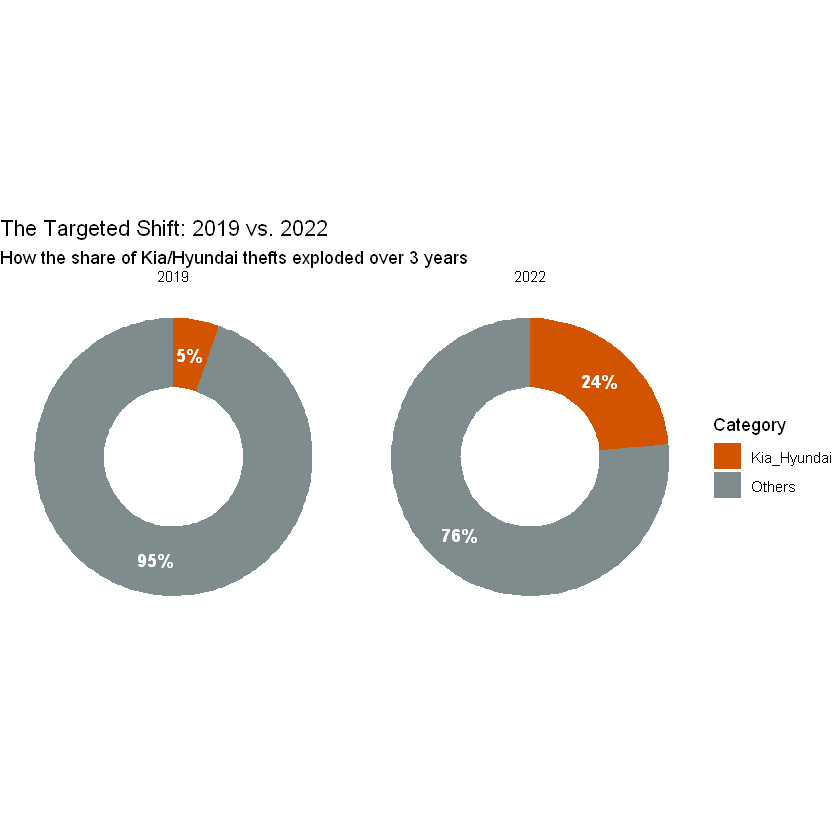

In [7]:
# 1. Filter for the start and end years to show the change
donut_comp_data <- theft_overall %>%
  filter(year %in% c(2019, 2022)) %>%
  group_by(year) %>%
  summarise(Kia_Hyundai = sum(countKiaHyundaiThefts),
            Others = sum(countOtherThefts)) %>%
  gather(key = "Category", value = "Count", -year) %>%
  group_by(year) %>%
  mutate(fraction = Count / sum(Count),
         ymax = cumsum(fraction),
         ymin = c(0, head(ymax, n=-1)),
         label = paste0(round(fraction * 100), "%"))

# 2. Plot Side-by-Side Donuts
ggplot(donut_comp_data, aes(ymax=ymax, ymin=ymin, xmax=4, xmin=3, fill=Category)) +
  geom_rect() +
  coord_polar(theta="y") +
  xlim(c(2, 4)) +
  facet_wrap(~year) + # This creates the side-by-side comparison
  theme_void() +
  scale_fill_manual(values = c("#D35400", "#7F8C8D")) +
  geom_text(aes(x=3.5, y=(ymin+ymax)/2, label=label), color="white", fontface="bold") +
  labs(title = "The Targeted Shift: 2019 vs. 2022",
       subtitle = "How the share of Kia/Hyundai thefts exploded over 3 years")

### 2.2(b) Create a Tree Map with highest volume of thefts by Geographic Density

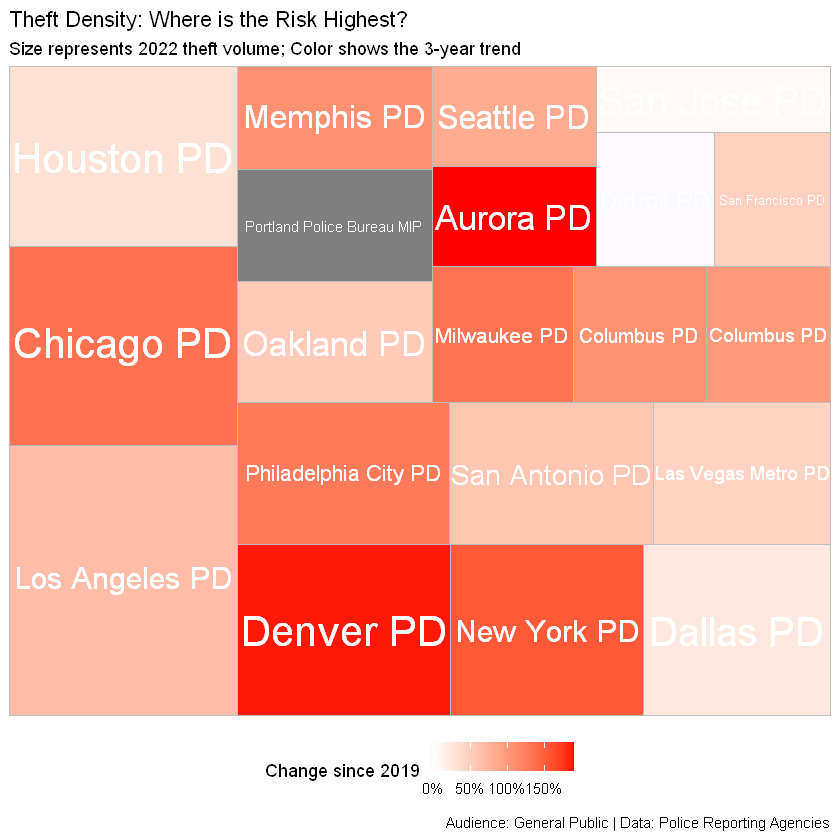

In [8]:
# 1. Clean the Map Data
theft_map_clean <- theft_map %>%
  mutate(
    countCarThefts2022 = as.numeric(countCarThefts2022)
  ) %>%
  filter(!is.na(countCarThefts2022) & countCarThefts2022 > 0) %>%
  # Selecting the top 20 areas to keep the Tree Map readable for the public
  top_n(20, countCarThefts2022)

# 2. Create the Tree Map
ggplot(theft_map_clean, aes(area = countCarThefts2022, fill = percentChange2019to2022, label = geo_name)) +
  geom_treemap() +
  geom_treemap_text(colour = "white", place = "centre", grow = TRUE) +
  scale_fill_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0,
                       labels = percent, name = "Change since 2019") +
  labs(
    title = "Theft Density: Where is the Risk Highest?",
    subtitle = "Size represents 2022 theft volume; Color shows the 3-year trend",
    caption = "Audience: General Public | Data: Police Reporting Agencies"
  ) +
  theme(legend.position = "bottom")

### 2.2(c) Create a Stacked Bar of cumulative car thefts volume by location (2019-2022)

Warning message:
"NAs introduced by coercion"Warning message:
"NAs introduced by coercion"

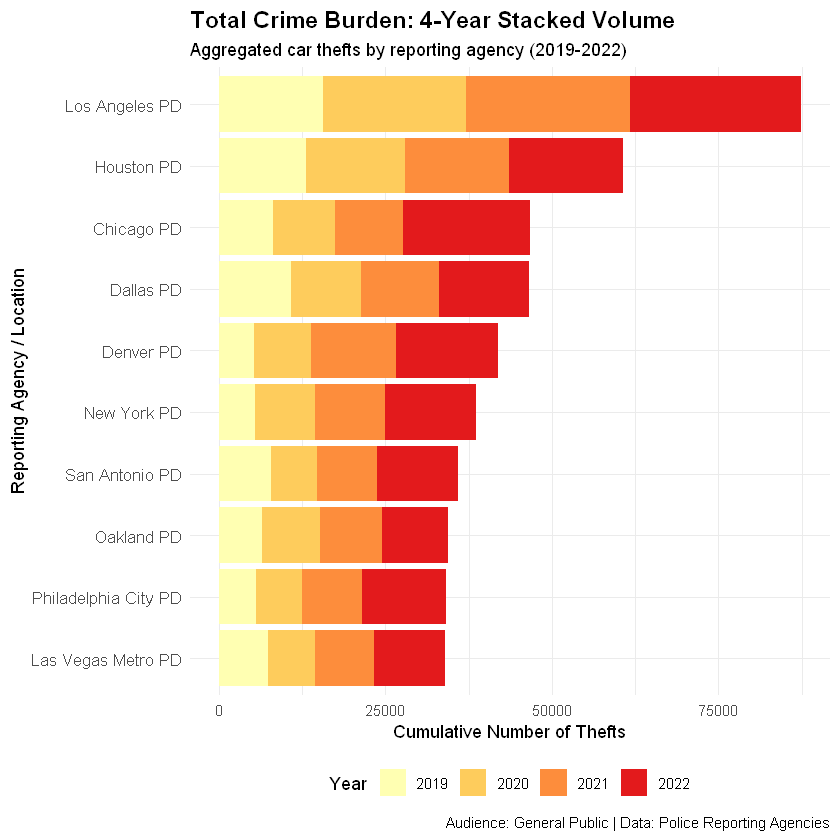

In [9]:
# 1. Clean and Transform the Map Data
# Select the top 10 agencies to ensure the labels are readable for the public
map_stacked_data <- theft_map %>%
  mutate(
    # Fixing capitalization and ensuring numeric types
    countCarThefts2020 = as.numeric(countCarThefts2020),
    countCarThefts2021 = as.numeric(countCarThefts2021)
  ) %>%
  # Focus on top 10 locations by 2022 volume
  top_n(10, countCarThefts2022) %>%
  # Pivot the years from columns into rows for stacking
  gather(key = "Year", value = "Theft_Count", 
         countCarThefts2019, countCarThefts2020, countCarThefts2021, countCarThefts2022) %>%
  # Clean up the labels (e.g., "countCarThefts2019" becomes "2019")
  mutate(Year = gsub("countCarThefts", "", Year))

# 2. Create the Stacked Bar Chart
ggplot(map_stacked_data, aes(x = reorder(geo_name, Theft_Count), y = Theft_Count, fill = Year)) +
  geom_bar(stat = "identity", position = position_stack(reverse = TRUE)) +
  coord_flip() + # Flip to ensure city names don't overlap
  scale_fill_brewer(palette = "YlOrRd") + # Yellow to Red "Heat" scale
  theme_minimal() +
  labs(
    title = "Total Crime Burden: 4-Year Stacked Volume",
    subtitle = "Aggregated car thefts by reporting agency (2019-2022)",
    x = "Reporting Agency / Location",
    y = "Cumulative Number of Thefts",
    fill = "Year",
    caption = "Audience: General Public | Data: Police Reporting Agencies"
  ) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14),
    axis.text.y = element_text(size = 10)
  )

### 2.2(d) Create a Stacked Area Chart of The Surge in Kia & Hyundai Thefts

Warning message:
"Removed 1 rows containing missing values (position_stack)."

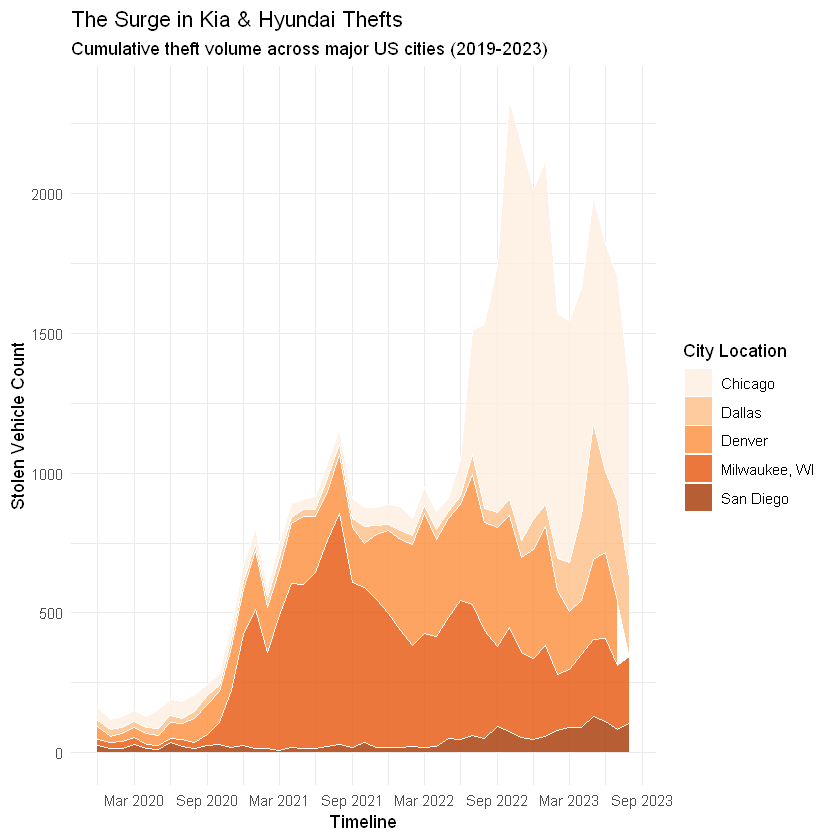

In [10]:
# 1. Clean the Motherboard Data
# Need to fix the column names manually because of the 'X' headers
theft_motherboard_clean <- theft_motherboard %>%
  # Row 1 contains "Kia/Hyundais", "All", "Percent" repeated. 
  # Extract the City names from the actual headers.
  slice(-1) %>% 
  rename(Date = X1) %>%
  filter(!is.na(Date)) %>%
  # Select the Date and the columns that represent Kia/Hyundai counts for major cities
  # Denver is Col 2, Chicago is Col 14, Milwaukee is Col 155
  select(Date, Denver, Chicago, `Milwaukee, WI`, Dallas, `San Diego`) %>%
  # Convert from "Wide" to "Long" format so City becomes a label
  gather(key = "City", value = "Theft_Count", -Date) %>%
  # Clean up the counts (remove any characters and convert to numeric)
  mutate(Theft_Count = as.numeric(gsub("[^0-9]", "", Theft_Count)))

# 2. Fix the Date Label formatting
# If Date looks like "Dec/19", then tell R it's a time object
theft_motherboard_clean$Date <- as.Date(paste0("01/", theft_motherboard_clean$Date), format="%d/%b/%y")

# 3. Visual #4: Stacked Area Chart (Required)
ggplot(theft_motherboard_clean, aes(x = Date, y = Theft_Count, fill = City)) +
  geom_area(alpha = 0.8, color = "white", size = 0.1) +
  scale_fill_brewer(palette = "Oranges") + # Consistent "Warning" theme
  scale_x_date(date_labels = "%b %Y", date_breaks = "6 months") +
  theme_minimal() +
  labs(
    title = "The Surge in Kia & Hyundai Thefts",
    subtitle = "Cumulative theft volume across major US cities (2019-2023)",
    x = "Timeline",
    y = "Stolen Vehicle Count",
    fill = "City Location"
  )

### 2.2(e) Create a Line Chart of Monthly Kia and Hyundai thefts (2019-2022)

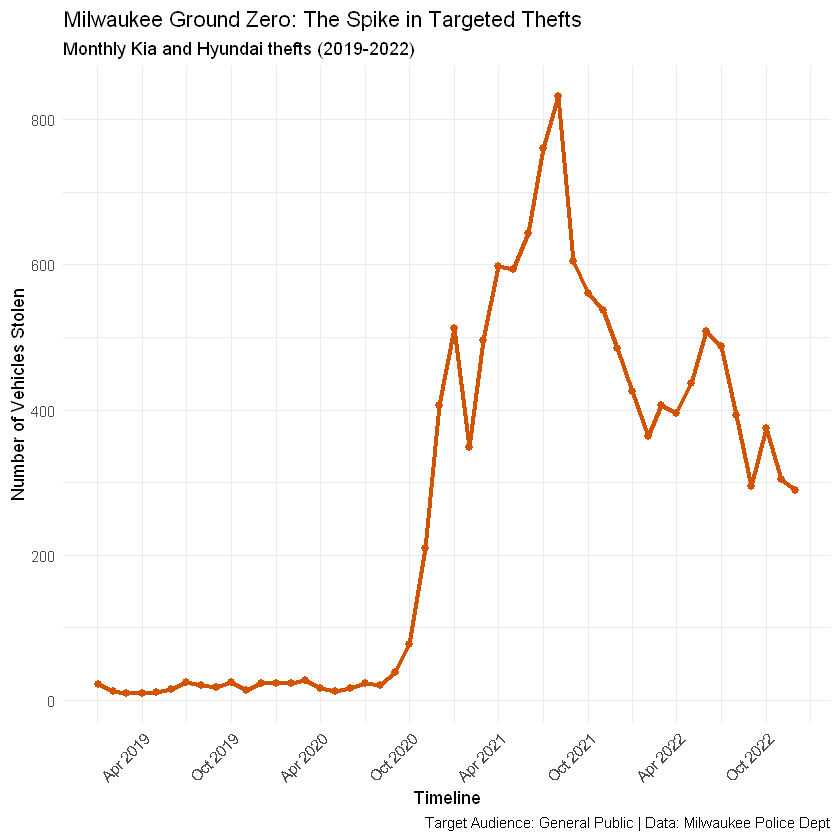

In [11]:
# 1. Prepare Milwaukee data
milwaukee_line <- theft_milwaukee %>%
  mutate(Date = as.Date(paste0("01-", month, "-", year), format="%d-%b-%Y")) %>%
  arrange(Date)

# 2. Create the Line Chart
ggplot(milwaukee_line, aes(x = Date, y = countKiaHyundaiThefts)) +
  geom_line(color = "#D35400", size = 1.2) +
  geom_point(color = "#D35400", size = 2) +
  theme_minimal() +
  scale_x_date(date_labels = "%b %Y", date_breaks = "6 months") +
  labs(
    title = "Milwaukee Ground Zero: The Spike in Targeted Thefts",
    subtitle = "Monthly Kia and Hyundai thefts (2019-2022)",
    x = "Timeline",
    y = "Number of Vehicles Stolen",
    caption = "Target Audience: General Public | Data: Milwaukee Police Dept"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

### 2.2(f) Create a Bar Chart of Total Kia/Hyundai Thefts vs. Other Thefts

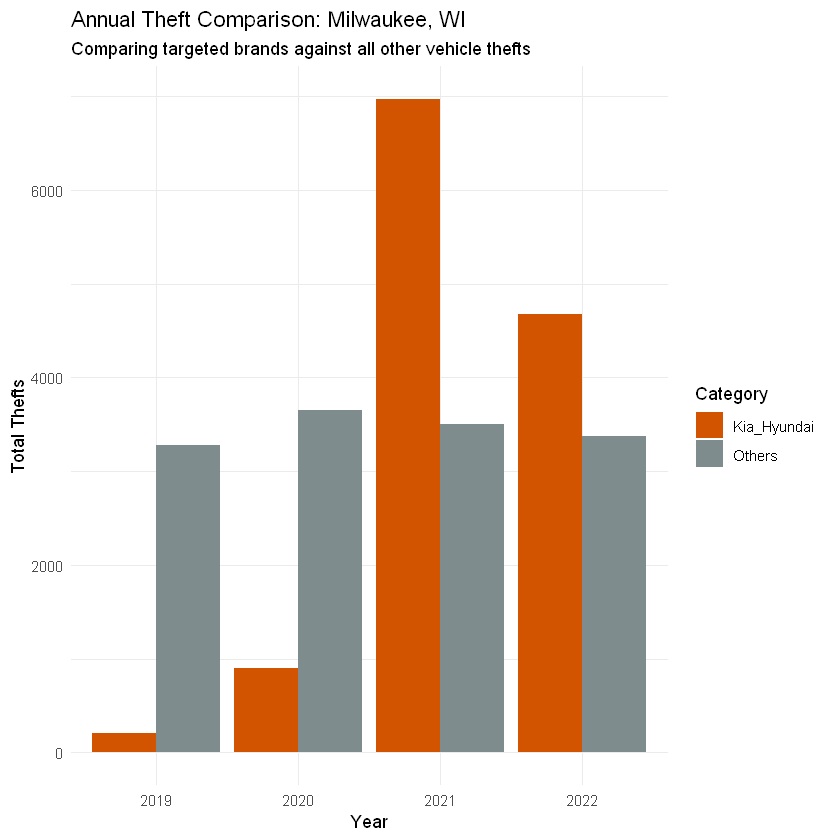

In [12]:
# 1. Aggregate by Year
milwaukee_yearly <- theft_milwaukee %>%
  group_by(year) %>%
  summarise(Kia_Hyundai = sum(countKiaHyundaiThefts),
            Others = sum(countOtherThefts)) %>%
  gather(key = "Vehicle_Type", value = "Total_Thefts", -year)

# 2. Create Comparison Bar Chart
ggplot(milwaukee_yearly, aes(x = as.factor(year), y = Total_Thefts, fill = Vehicle_Type)) +
  geom_bar(stat = "identity", position = "dodge") +
  scale_fill_manual(values = c("#D35400", "#7F8C8D")) +
  theme_minimal() +
  labs(
    title = "Annual Theft Comparison: Milwaukee, WI",
    subtitle = "Comparing targeted brands against all other vehicle thefts",
    x = "Year",
    y = "Total Thefts",
    fill = "Category"
  )